# Rossmann Store Sales — Phase 4.5: Output Calibration + Ensembling

Phases 1-4 produced a best RMSPE of 0.1412 against a Phase 1 baseline of 0.1448 — only a 2.5% relative gain for a lot of engineering. Two things were never applied, both of which the project already had the evidence for:

1. **Output calibration.** Phase 1 established that RMSPE is *not* minimized by the conditional mean — a flat 2% shrink of the baseline improved it from 0.147 to 0.1448. That finding was never carried into Phases 2-4, which all predict `expm1(model output)` with no correction. RMSPE weights each row by `1/y²`, so low-sales days dominate the score and the optimal predictor sits meaningfully below the conditional mean.
2. **Ensembling.** Phase 3's HGB and Phase 4's MLP score identically (0.1412) but fail differently — the MLP's worst day is Friday, HGB's problem day is Sunday. Models that are equally good but wrong in different places are exactly the case where averaging helps.

**Discipline:** the shrink factor and ensemble weights are fitted on the *inner* split only (models retrained on `inner_train`, fitted against `inner_val`), then frozen and applied unchanged to the Phase 3/4 validation predictions. Nothing here is tuned against `val_fold`. `test.csv` stays unseen until Phase 5.

In [1]:
import json
import time
import numpy as np
import pandas as pd
import torch
import plotly.express as px
import plotly.io as pio
pio.templates.default = "plotly_white"

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

from rossmann_features import (
    prepare_store_table, add_features, CATEGORICAL_COLS, NUMERIC_COLS,
    add_rolling_features_training, add_rolling_features_frozen, ROLLING_WINDOWS,
    add_yearago_lag, fit_store_dow_promo_mean, predict_store_dow_promo_mean,
    fit_store_target_encoding, add_store_target_encoding,
)
import rossmann_nn as rnn

rmspe = rnn.rmspe
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

train = pd.read_csv("train.csv", parse_dates=["Date"], low_memory=False, dtype={"StateHoliday": str})
store = pd.read_csv("store.csv")
store_prepared = prepare_store_table(store)

with open("phase1_split_config.json") as f:
    split_cfg = json.load(f)
val_start = pd.Timestamp(split_cfg["val_start"])
train_fold = add_features(train[train["Date"] < val_start].copy(), store_prepared)
train_fold_open = train_fold[train_fold["Open"] == 1]
train_fit = train_fold[(train_fold["Open"] == 1) & (train_fold["Sales"] > 0)].copy()

# Inner split -- identical construction to Phases 3 and 4.
inner_val_start = train_fold["Date"].max() - pd.Timedelta(days=41)
inner_cutoff = inner_val_start - pd.Timedelta(days=1)
inner_train_raw = train_fit[train_fit["Date"] < inner_val_start].copy()
inner_val_raw = train_fold[(train_fold["Date"] >= inner_val_start) & (train_fold["Open"] == 1)].copy()
inner_history_open = train_fold_open[train_fold_open["Date"] <= inner_cutoff]
print("inner_train:", inner_train_raw["Date"].min().date(), "-", inner_train_raw["Date"].max().date())
print("inner_val:  ", inner_val_raw["Date"].min().date(), "-", inner_val_raw["Date"].max().date())


device: cuda


inner_train: 2013-01-01 - 2015-05-08
inner_val:   2015-05-09 - 2015-06-19


In [2]:
# Inner-split feature build -- same shared pipeline as Phase 3/4, fit on inner history only.
inner_sd_table = fit_store_dow_promo_mean(inner_history_open)
inner_global_mean = inner_history_open["Sales"].mean()
inner_store_encoding = fit_store_target_encoding(inner_history_open)
inner_global_mean_log = np.log1p(inner_history_open["Sales"]).mean()

def build_inner_dataset(df, mode):
    if mode == "training":
        df = add_rolling_features_training(df)
    else:
        df = add_rolling_features_frozen(df, inner_history_open, inner_cutoff)
    fallback = predict_store_dow_promo_mean(df, inner_sd_table, inner_global_mean)
    df = add_yearago_lag(df, inner_history_open, fallback)
    df = add_store_target_encoding(df, inner_store_encoding, inner_global_mean_log)
    return df

inner_train = build_inner_dataset(inner_train_raw, mode="training")
inner_val = build_inner_dataset(inner_val_raw, mode="frozen")

LAG_COLS = [f"SalesRollMean{w}" for w in ROLLING_WINDOWS] + [f"CustomersRollMean{w}" for w in ROLLING_WINDOWS] + \
           ["SalesYearAgo", "HorizonDay"]
TREE_CATEGORICAL_COLS = ["DayOfWeek", "Month", "StoreType", "Assortment", "StateHoliday"]
TREE_NUMERIC_COLS = NUMERIC_COLS + LAG_COLS + ["StoreMeanLogSales"]
TREE_CAT_IDX = list(range(len(TREE_CATEGORICAL_COLS)))
RIDGE_NUMERIC_COLS = NUMERIC_COLS + LAG_COLS
NN_NUMERIC_COLS = NUMERIC_COLS + LAG_COLS

inner_y_log = np.log1p(inner_train["Sales"].to_numpy())
inner_val_sales = inner_val["Sales"].to_numpy()
inner_val_open = inner_val["Open"].to_numpy()
print("inner_train rows:", len(inner_train), "| inner_val rows:", len(inner_val))

inner_train rows: 766584 | inner_val rows: 37473


In [3]:
# Retrain the Phase 3 models on inner_train, with Phase 3's chosen hyperparameters, to get
# honest inner-split predictions to calibrate against.
#
# Acknowledged mild circularity: those hyperparameters (ridge alpha=10, RF n_estimators=200,
# HGB max_iter=700) were themselves selected on this same inner split back in Phase 3, so
# the inner predictions are slightly optimistic. The calibration constants fitted from them
# could therefore be a touch conservative. That's the reason for the explicit
# transferability check further down rather than just asserting the transfer works.
def finish(pred_log, open_flag):
    pred = np.clip(np.expm1(pred_log), 0, None)
    return np.where(open_flag == 0, 0, pred)

inner_preds = {}
t0 = time.time()

ridge_pipe = Pipeline([
    ("features", ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=True), CATEGORICAL_COLS),
        ("num", "passthrough", RIDGE_NUMERIC_COLS),
    ])),
    ("scale", StandardScaler(with_mean=False)),
])
X_tr_ridge = ridge_pipe.fit_transform(inner_train)
X_ev_ridge = ridge_pipe.transform(inner_val)
ridge = Ridge(alpha=10.0).fit(X_tr_ridge, inner_y_log)
inner_preds["ridge_lags"] = finish(ridge.predict(X_ev_ridge), inner_val_open)
print(f"ridge done ({time.time()-t0:.0f}s) inner RMSPE = {rmspe(inner_val_sales, inner_preds['ridge_lags']):.4f}")

tree_encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
X_tr_tree = np.hstack([tree_encoder.fit_transform(inner_train[TREE_CATEGORICAL_COLS]),
                        inner_train[TREE_NUMERIC_COLS].to_numpy()])
X_ev_tree = np.hstack([tree_encoder.transform(inner_val[TREE_CATEGORICAL_COLS]),
                        inner_val[TREE_NUMERIC_COLS].to_numpy()])

rf = RandomForestRegressor(n_estimators=200, max_depth=16, min_samples_leaf=15, max_samples=0.25,
                            n_jobs=-1, random_state=0).fit(X_tr_tree, inner_y_log)
inner_preds["rf"] = finish(rf.predict(X_ev_tree), inner_val_open)
print(f"rf done ({time.time()-t0:.0f}s) inner RMSPE = {rmspe(inner_val_sales, inner_preds['rf']):.4f}")

hgb = HistGradientBoostingRegressor(categorical_features=TREE_CAT_IDX, learning_rate=0.1, max_iter=700,
                                     early_stopping=False, random_state=0).fit(X_tr_tree, inner_y_log)
inner_preds["hgb"] = finish(hgb.predict(X_ev_tree), inner_val_open)
print(f"hgb done ({time.time()-t0:.0f}s) inner RMSPE = {rmspe(inner_val_sales, inner_preds['hgb']):.4f}")


ridge done (2s) inner RMSPE = 0.1803


rf done (50s) inner RMSPE = 0.1532


hgb done (61s) inner RMSPE = 0.1442


nn done (323s, best epoch 23) inner RMSPE = 0.1390


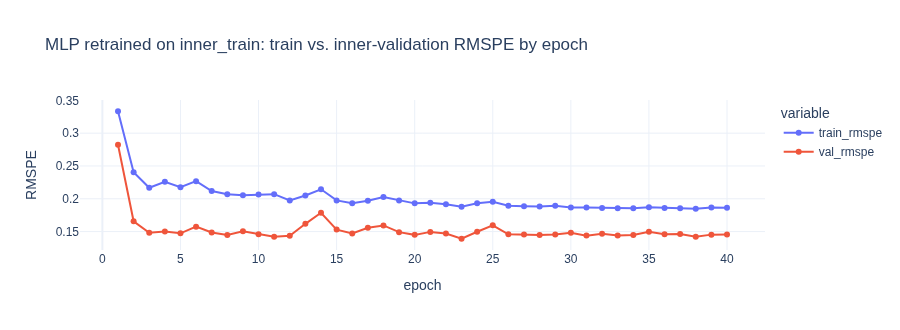

In [4]:
# The MLP, retrained on inner_train via the shared rossmann_nn module (~6 min on GPU).
_, cardinalities, inner_train_cat, (inner_val_cat,) = rnn.encode_categoricals(inner_train, [inner_val])
nn_scaler = StandardScaler()
inner_train_num = nn_scaler.fit_transform(inner_train[NN_NUMERIC_COLS].to_numpy())
inner_val_num = nn_scaler.transform(inner_val[NN_NUMERIC_COLS].to_numpy())

t0 = time.time()
model_nn, nn_history, nn_best_epoch = rnn.train_nn(
    cardinalities, rnn.NN_CATEGORICAL_COLS, rnn.EMB_DIMS, len(NN_NUMERIC_COLS),
    inner_train_cat, inner_train_num, inner_y_log, inner_train["Sales"].to_numpy(), inner_train["Open"].to_numpy(),
    inner_val_cat, inner_val_num, inner_val_sales, inner_val_open, device,
    epochs=40, batch_size=1024, verbose=False,
)
inner_preds["nn"] = finish(rnn.predict_in_batches(model_nn, inner_val_cat, inner_val_num, device), inner_val_open)
print(f"nn done ({time.time()-t0:.0f}s, best epoch {nn_best_epoch}) "
      f"inner RMSPE = {rmspe(inner_val_sales, inner_preds['nn']):.4f}")

fig = px.line(nn_history, x="epoch", y=["train_rmspe", "val_rmspe"], markers=True,
              title="MLP retrained on inner_train: train vs. inner-validation RMSPE by epoch")
fig.update_layout(height=330, yaxis_title="RMSPE")
fig.show()


     model  inner_rmspe  factor  inner_rmspe_calibrated     gain
ridge_lags     0.180261   0.964                0.176461 0.003800
        rf     0.153196   0.954                0.145593 0.007604
       hgb     0.144197   0.951                0.134868 0.009329
        nn     0.139050   0.961                0.133023 0.006027


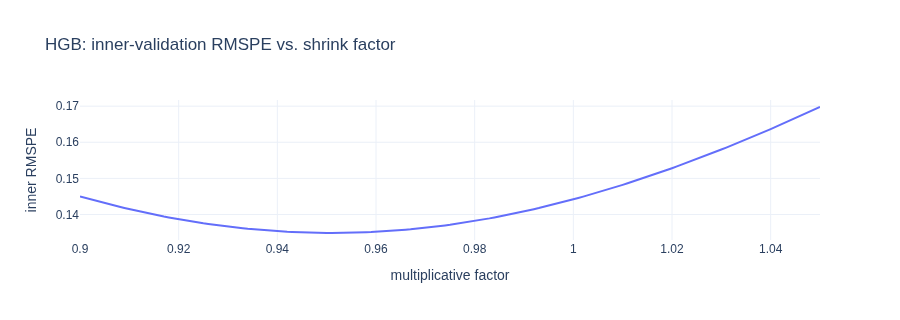

In [5]:
# Step 1: per-model shrink factor, fitted on inner_val only.
GRID = np.arange(0.90, 1.0501, 0.001)

def best_factor(pred, sales):
    scores = [rmspe(sales, pred * f) for f in GRID]
    i = int(np.argmin(scores))
    return float(GRID[i]), float(scores[i])

MODELS = ["ridge_lags", "rf", "hgb", "nn"]
factors = {}
rows = []
for m in MODELS:
    f, sc = best_factor(inner_preds[m], inner_val_sales)
    factors[m] = f
    base = rmspe(inner_val_sales, inner_preds[m])
    rows.append({"model": m, "inner_rmspe": base, "factor": f, "inner_rmspe_calibrated": sc,
                 "gain": base - sc})
factor_df = pd.DataFrame(rows)
print(factor_df.to_string(index=False))

fig = px.line(x=GRID, y=[rmspe(inner_val_sales, inner_preds["hgb"] * f) for f in GRID],
              title="HGB: inner-validation RMSPE vs. shrink factor")
fig.update_layout(height=320, xaxis_title="multiplicative factor", yaxis_title="inner RMSPE")
fig.show()

In [6]:
# Step 2: ensemble weights + a single shared shrink factor, fitted on inner_val.
# Weighting happens in log space (matching the log1p target the models were trained on),
# so this is a weighted geometric mean. Weights live on the simplex, letting a model that
# doesn't earn its place get weight 0.
#
# A deterministic grid over the simplex rather than a general-purpose optimizer: the
# weights are scale-degenerate (only their ratios matter), which makes Nelder-Mead wander,
# and the whole search is only ~1,771 points -- cheap enough to just evaluate exhaustively
# and get a reproducible answer.
EPS = 1.0
log_preds = np.column_stack([np.log(inner_preds[m] + EPS) for m in MODELS])

def blend(weights, factor, logp, open_flag):
    pred = np.exp(logp @ weights) - EPS
    pred = np.clip(pred, 0, None) * factor
    return np.where(open_flag == 0, 0, pred)

STEP = 0.05
units = int(round(1 / STEP))
weight_grid = np.array([(a, b, c, units - a - b - c)
                        for a in range(units + 1)
                        for b in range(units + 1 - a)
                        for c in range(units + 1 - a - b)], dtype=float) * STEP
print(f"simplex grid: {len(weight_grid)} weight combinations at step {STEP}")

# Weights and factor interact (the factor rescales a blend whose optimum shifts slightly),
# so alternate between them until both stop moving -- converges in 2-3 passes.
ENSEMBLE_FACTOR = 1.0
for it in range(3):
    scores = [rmspe(inner_val_sales, blend(w, ENSEMBLE_FACTOR, log_preds, inner_val_open)) for w in weight_grid]
    ENSEMBLE_WEIGHTS = weight_grid[int(np.argmin(scores))]
    blended_raw = np.exp(log_preds @ ENSEMBLE_WEIGHTS) - EPS
    ENSEMBLE_FACTOR, inner_ens_rmspe = best_factor(np.clip(blended_raw, 0, None), inner_val_sales)
    print(f"  pass {it+1}: weights={np.round(ENSEMBLE_WEIGHTS, 2)} factor={ENSEMBLE_FACTOR:.3f} "
          f"inner RMSPE={inner_ens_rmspe:.4f}")

print("\nfitted on inner_val (frozen from here on):")
for m, w in zip(MODELS, ENSEMBLE_WEIGHTS):
    print(f"  weight[{m:11}] = {w:.2f}")
print(f"  shared shrink factor = {ENSEMBLE_FACTOR:.3f}")
print(f"  inner RMSPE          = {inner_ens_rmspe:.4f}")
print(f"  best single model (calibrated) = {factor_df.inner_rmspe_calibrated.min():.4f}")


simplex grid: 1771 weight combinations at step 0.05


  pass 1: weights=[0.1  0.15 0.2  0.55] factor=0.963 inner RMSPE=0.1277


  pass 2: weights=[0.05 0.15 0.3  0.5 ] factor=0.961 inner RMSPE=0.1274


  pass 3: weights=[0.05 0.15 0.3  0.5 ] factor=0.961 inner RMSPE=0.1274

fitted on inner_val (frozen from here on):
  weight[ridge_lags ] = 0.05
  weight[rf         ] = 0.15
  weight[hgb        ] = 0.30
  weight[nn         ] = 0.50
  shared shrink factor = 0.961
  inner RMSPE          = 0.1274
  best single model (calibrated) = 0.1330


In [7]:
# Step 3: apply the frozen factors/weights to the SAVED Phase 3/4 val_fold predictions.
# Those came from models trained on the full train_fold; nothing below is refitted.
p3 = pd.read_csv("phase3_val_predictions.csv", parse_dates=["Date"])
p4 = pd.read_csv("phase4_val_predictions.csv", parse_dates=["Date"])
assert (p3["Store"].values == p4["Store"].values).all() and (p3["Date"].values == p4["Date"].values).all()

val = p3[["Store", "Date", "Sales", "Open"]].copy()
outer_preds = {"ridge_lags": p3["pred_ridge_lags"].to_numpy(), "rf": p3["pred_rf"].to_numpy(),
                "hgb": p3["pred_hgb"].to_numpy(), "nn": p4["pred_nn"].to_numpy()}
val_sales = val["Sales"].to_numpy()
val_open = val["Open"].to_numpy()

outer_log = np.column_stack([np.log(outer_preds[m] + EPS) for m in MODELS])
pred_ensemble = blend(ENSEMBLE_WEIGHTS, ENSEMBLE_FACTOR, outer_log, val_open)

rows = []
for m in MODELS:
    raw = rmspe(val_sales, outer_preds[m])
    cal = rmspe(val_sales, np.where(val_open == 0, 0, outer_preds[m] * factors[m]))
    rows.append({"model": m, "val_rmspe_raw": raw, "val_rmspe_calibrated": cal, "factor_used": factors[m]})
rows.append({"model": "ENSEMBLE (calibrated)", "val_rmspe_raw": np.nan,
             "val_rmspe_calibrated": rmspe(val_sales, pred_ensemble), "factor_used": ENSEMBLE_FACTOR})
final_df = pd.DataFrame(rows)
print(final_df.to_string(index=False))
print()
print(f"Phase 1 baseline           : 0.1448")
print(f"Phase 3/4 best (uncalibrated): 0.1412")
print(f"Phase 4.5 ensemble         : {rmspe(val_sales, pred_ensemble):.4f}")

                model  val_rmspe_raw  val_rmspe_calibrated  factor_used
           ridge_lags       0.176052              0.166805        0.964
                   rf       0.145959              0.134035        0.954
                  hgb       0.141216              0.130116        0.951
                   nn       0.141201              0.132837        0.961
ENSEMBLE (calibrated)            NaN              0.125739        0.961

Phase 1 baseline           : 0.1448
Phase 3/4 best (uncalibrated): 0.1412
Phase 4.5 ensemble         : 0.1257


In [8]:
# Transferability check: the factors were fitted on models trained on inner_train (less
# data, earlier period) but applied to models trained on train_fold. If that transfer is
# sound, the inner-fitted factor should land near the factor val_fold would have chosen.
# The val-optimal column below is DIAGNOSTIC ONLY -- it is not used for any prediction.
print(f"{'model':<12} {'inner-fitted':>13} {'val-optimal':>12} {'gap':>7}")
for m in MODELS:
    f_val, _ = best_factor(outer_preds[m], val_sales)
    print(f"{m:<12} {factors[m]:>13.3f} {f_val:>12.3f} {factors[m]-f_val:>+7.3f}")
f_val_ens, sc_val_ens = best_factor(np.exp(outer_log @ ENSEMBLE_WEIGHTS) - EPS, val_sales)
print(f"{'ensemble':<12} {ENSEMBLE_FACTOR:>13.3f} {f_val_ens:>12.3f} {ENSEMBLE_FACTOR-f_val_ens:>+7.3f}")
print(f"\nhow much was left on the table by not cheating: "
      f"{rmspe(val_sales, pred_ensemble) - sc_val_ens:+.4f} RMSPE")

model         inner-fitted  val-optimal     gap
ridge_lags           0.964        0.942  +0.022
rf                   0.954        0.944  +0.010
hgb                  0.951        0.947  +0.004
nn                   0.961        0.953  +0.008


ensemble             0.961        0.953  +0.008

how much was left on the table by not cheating: +0.0003 RMSPE


RMSPE by DayOfWeek (1=Mon ... 7=Sun):
   HGB raw  ensemble
1   0.1149    0.1082
2   0.1473    0.1288
3   0.1237    0.1134
4   0.1303    0.1071
5   0.1464    0.1490
6   0.1758    0.1403
7   0.1589    0.1641

RMSPE by horizon week:
   HGB raw  ensemble
1   0.1081    0.1050
2   0.1495    0.1444
3   0.1648    0.1358
4   0.1339    0.1048
5   0.1353    0.1156
6   0.1491    0.1421



Saved phase45_calibration_results.csv, phase45_val_predictions.csv, phase45_calibration_params.json


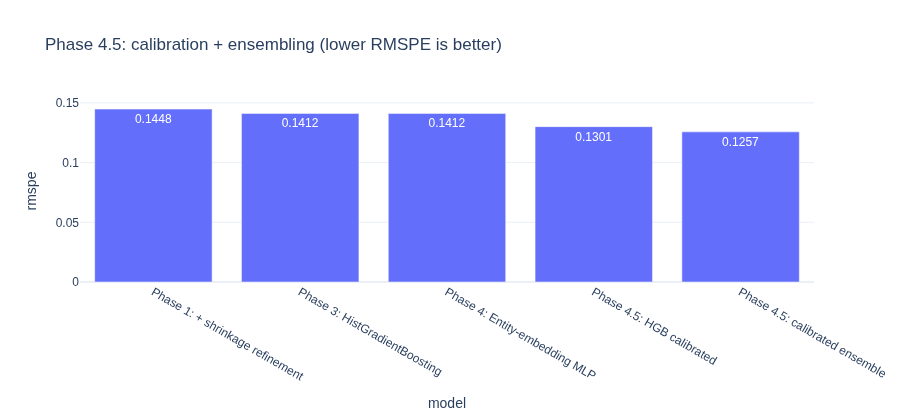

In [9]:
val["pred_hgb_raw"] = outer_preds["hgb"]
val["pred_ensemble"] = pred_ensemble
val["pred_hgb_calibrated"] = np.where(val_open == 0, 0, outer_preds["hgb"] * factors["hgb"])
val["DayOfWeek"] = val["Date"].dt.dayofweek + 1  # pandas Mon=0..Sun=6 -> Rossmann Mon=1..Sun=7
cutoff = pd.Timestamp("2015-06-19")
val["horizon_week"] = ((val["Date"] - cutoff).dt.days - 1) // 7 + 1

# Slice off dataframe columns rather than indexing the raw arrays with `g.index` --
# positional-vs-label indexing after a groupby is exactly the misalignment trap that has
# already produced two silent bugs in this project.
def rmspe_by(col):
    return pd.DataFrame({k: {"HGB raw": rmspe(g["Sales"], g["pred_hgb_raw"]),
                              "ensemble": rmspe(g["Sales"], g["pred_ensemble"])}
                         for k, g in val.groupby(col)}).T

print("RMSPE by DayOfWeek (1=Mon ... 7=Sun):")
print(rmspe_by("DayOfWeek").round(4).to_string())
print("\nRMSPE by horizon week:")
print(rmspe_by("horizon_week").round(4).to_string())

results_df = pd.DataFrame([
    {"model": "Phase 1: + shrinkage refinement", "rmspe": 0.1448},
    {"model": "Phase 3: HistGradientBoosting", "rmspe": 0.1412},
    {"model": "Phase 4: Entity-embedding MLP", "rmspe": 0.1412},
    {"model": "Phase 4.5: HGB calibrated", "rmspe": rmspe(val_sales, val["pred_hgb_calibrated"])},
    {"model": "Phase 4.5: calibrated ensemble", "rmspe": rmspe(val_sales, pred_ensemble)},
])
results_df.to_csv("phase45_calibration_results.csv", index=False)
val.to_csv("phase45_val_predictions.csv", index=False)
with open("phase45_calibration_params.json", "w") as f:
    json.dump({"models": MODELS, "weights": ENSEMBLE_WEIGHTS.tolist(),
               "factor": ENSEMBLE_FACTOR, "per_model_factors": factors}, f, indent=2)
print("\nSaved phase45_calibration_results.csv, phase45_val_predictions.csv, phase45_calibration_params.json")

fig = px.bar(results_df.sort_values("rmspe", ascending=False), x="model", y="rmspe",
             title="Phase 4.5: calibration + ensembling (lower RMSPE is better)", text_auto=".4f")
fig.update_layout(height=420)
fig.show()
